In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np  

In [6]:
df = pd.read_csv("/Users/antoniosirignano/Desktop/TIROCINO/water_mk1/data/history_last_4_years_irr_noirr_28_07.csv")
df['ts'] = pd.to_datetime(df['ts'])

# MISSING VALUE ANALYSIS   

/var/folders/_c/gt0qxdbj2v9090_442y4zb000000gn/T/ipykernel_39523/3762780540.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing.index, y=missing.values, palette='viridis')


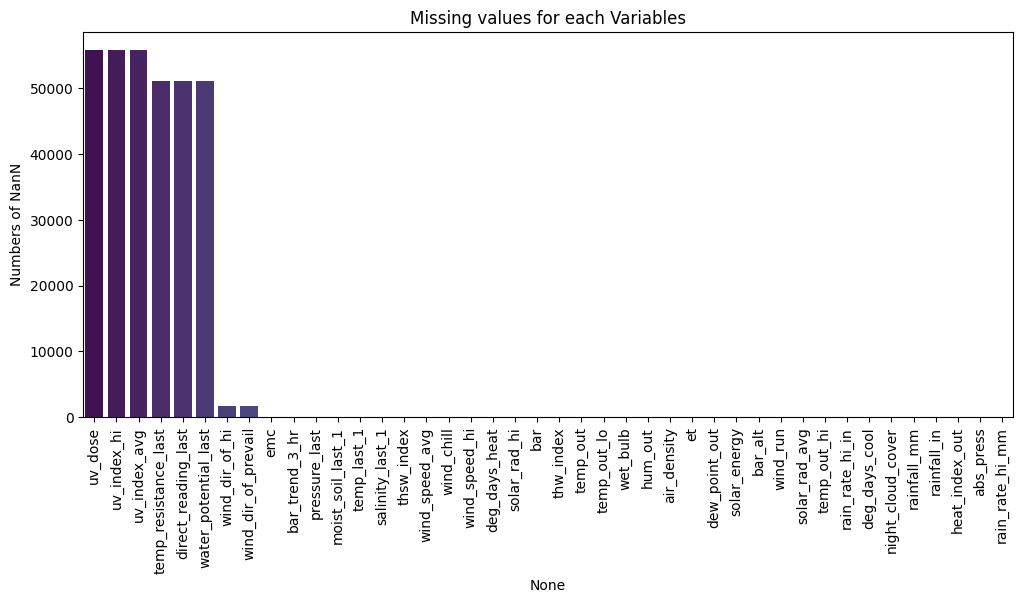

In [7]:
plt.figure(figsize=(12, 5))
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
sns.barplot(x=missing.index, y=missing.values, palette='viridis')
plt.xticks(rotation=90)
plt.title('Missing values for each Variables')
plt.ylabel('Numbers of NanN')
plt.show()

In [8]:
df_wp = df.dropna(subset=['water_potential_last'])

In [20]:
starting_rows = len(df)

# 3. Conteggio finale delle righe disponibili per il Machine Learning
final_rows = len(df_wp)
perc = (final_rows / starting_rows) * 100

# 4. Stampa dei risultati
print(f"Righe iniziali nel dataset: {starting_rows:,}")
print(f"Righe rimanenti dopo dropna: {final_rows:,}")
print(f"Percentuale di dati con target valido: {perc:.2f}%")

Righe iniziali nel dataset: 55,787
Righe rimanenti dopo dropna: 4,590
Percentuale di dati con target valido: 8.23%


# TARGET DISTRIBUTION  

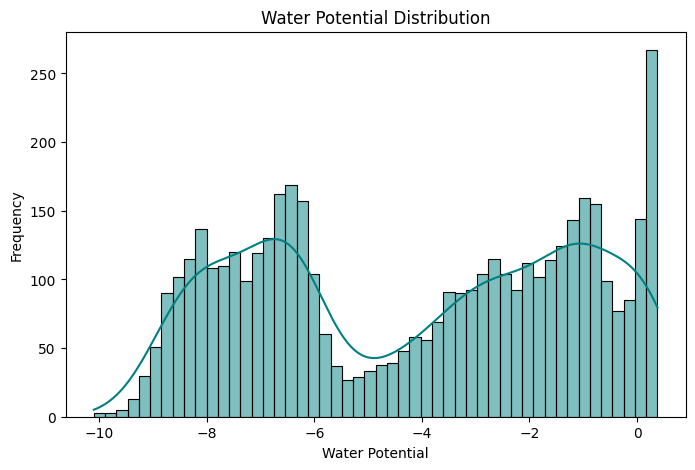

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df_wp['water_potential_last'], bins=50, kde=True, color='teal')
plt.title('Water Potential Distribution')
plt.xlabel('Water Potential')
plt.ylabel('Frequency')
plt.show()

# CORRELATION MATRIX  

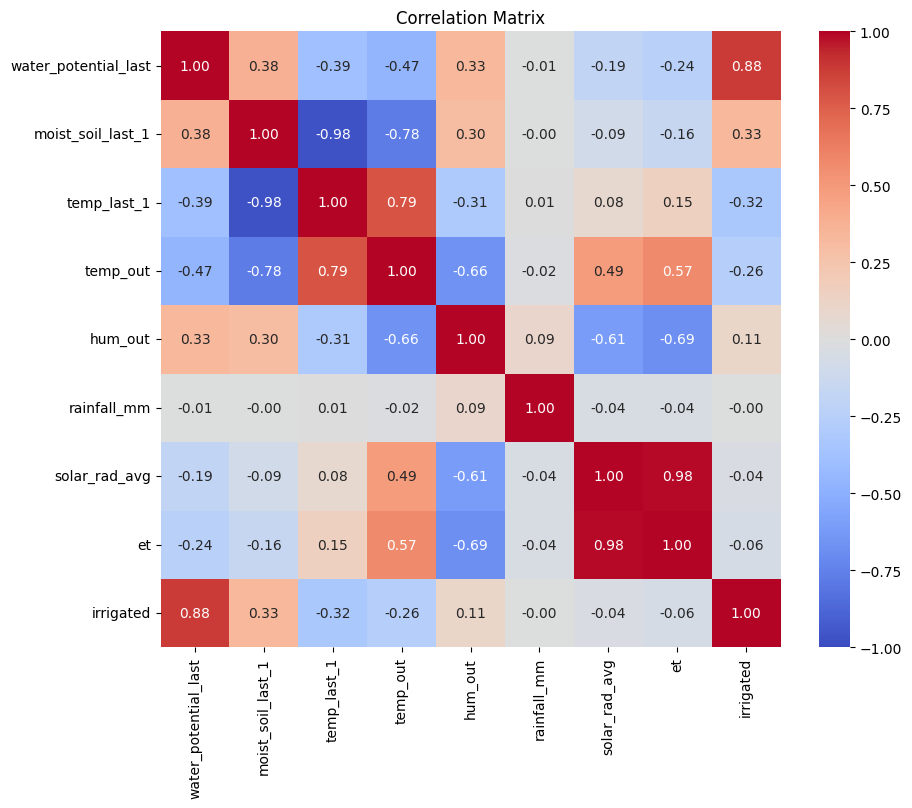

In [12]:
key_cols = ['water_potential_last',
            'moist_soil_last_1',
            'temp_last_1',
            'temp_out',
            'hum_out',
            'rainfall_mm',
            'solar_rad_avg',
            'et',
            'irrigated'] 

corr = df_wp[key_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

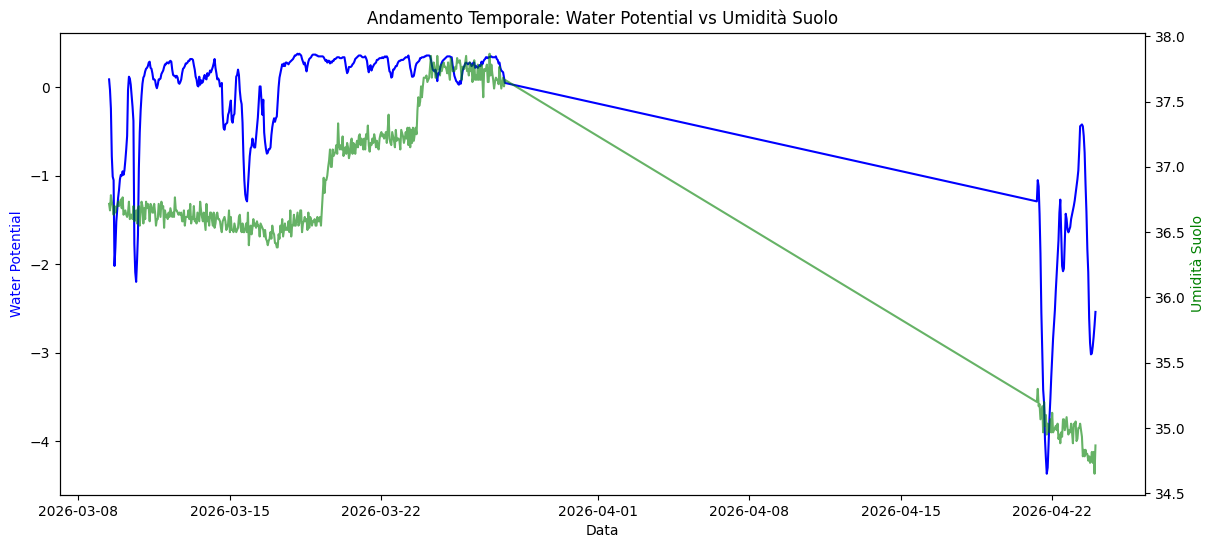

In [13]:
sample = df_wp.head(500)
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(sample['ts'], sample['water_potential_last'], color='b', label='Water Potential')
ax1.set_ylabel('Water Potential', color='b')
ax1.set_xlabel('Data')

ax2 = ax1.twinx()
ax2.plot(sample['ts'], sample['moist_soil_last_1'], color='g', label='Moist Soil', alpha=0.6)
ax2.set_ylabel('Umidità Suolo', color='g')

plt.title('Andamento Temporale: Water Potential vs Umidità Suolo')
plt.show()

# EXTENSION 


In [14]:
cols_to_drop = [c for c in df_wp if df_wp[c].isnull().all() or df_wp[c].nunique() <= 1]
df_ml = df_wp.drop(columns=cols_to_drop)

In [15]:
numeric_cols = df_ml.select_dtypes(include=[np.number]).columns

# Pearson Correlation Coefficient

$$ \frac{\sum_{i=1}^{n} (x_i - x)(y_i - y)}{\sqrt{\sum_{i=1}^{n} (x_i - x)^2}\sqrt{\sum_{i=1}^{n} (y_i - y)^2}} $$


/var/folders/_c/gt0qxdbj2v9090_442y4zb000000gn/T/ipykernel_39523/759349902.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette='coolwarm')


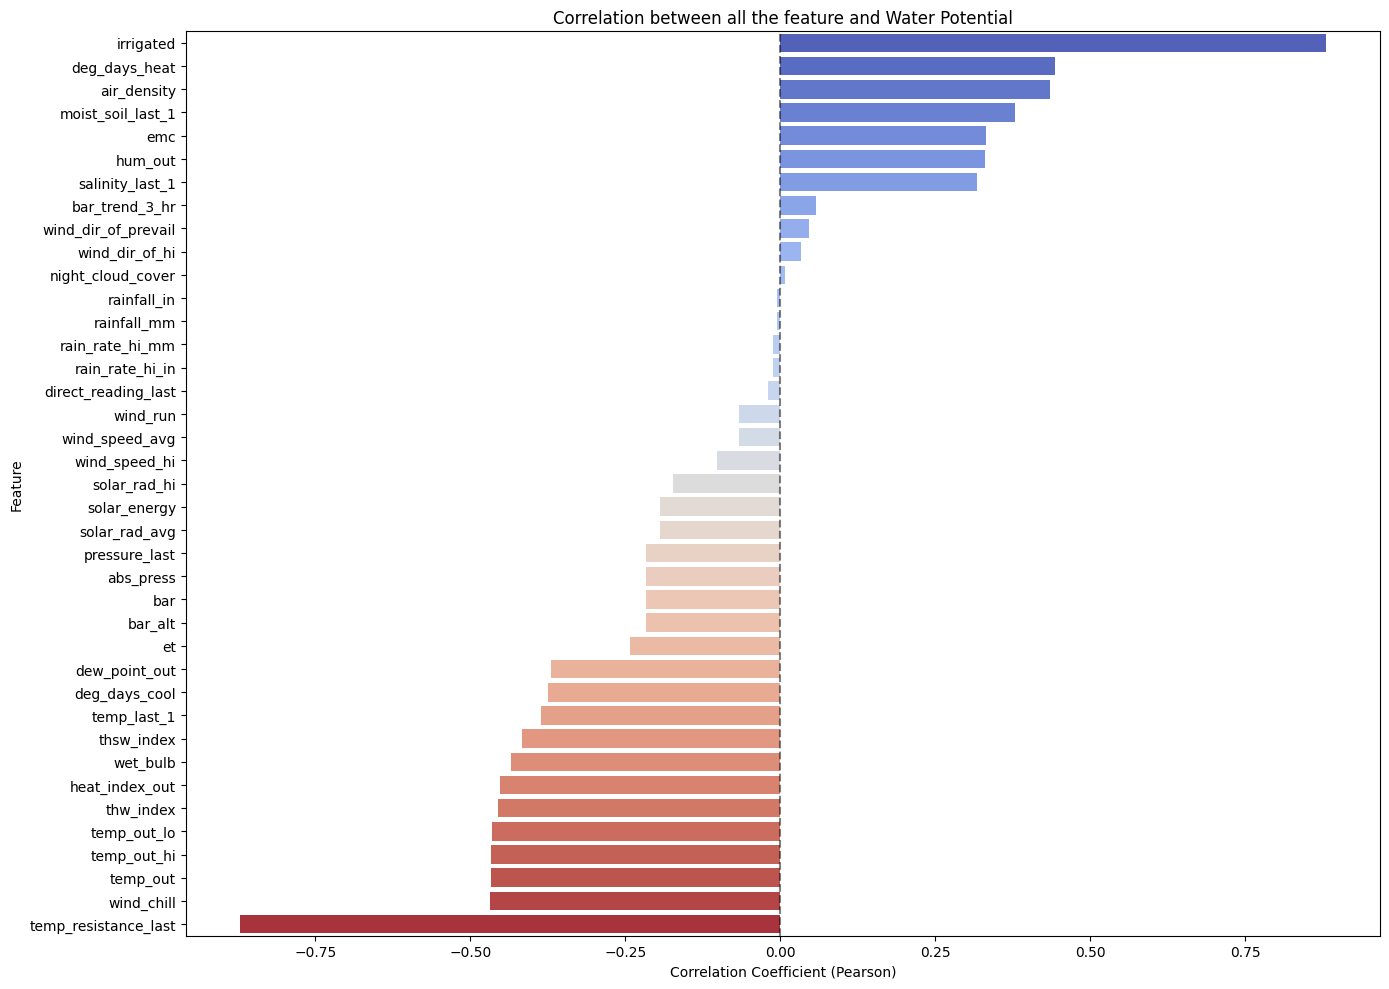

In [16]:
corr_with_target = df_ml[numeric_cols].corr()['water_potential_last'].sort_values(ascending=False)
corr_with_target = corr_with_target.drop('water_potential_last')

plt.figure(figsize=(14, 10))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette='coolwarm')
plt.title('Correlation between all the feature and Water Potential')
plt.xlabel('Correlation Coefficient (Pearson)')
plt.ylabel('Feature')
plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

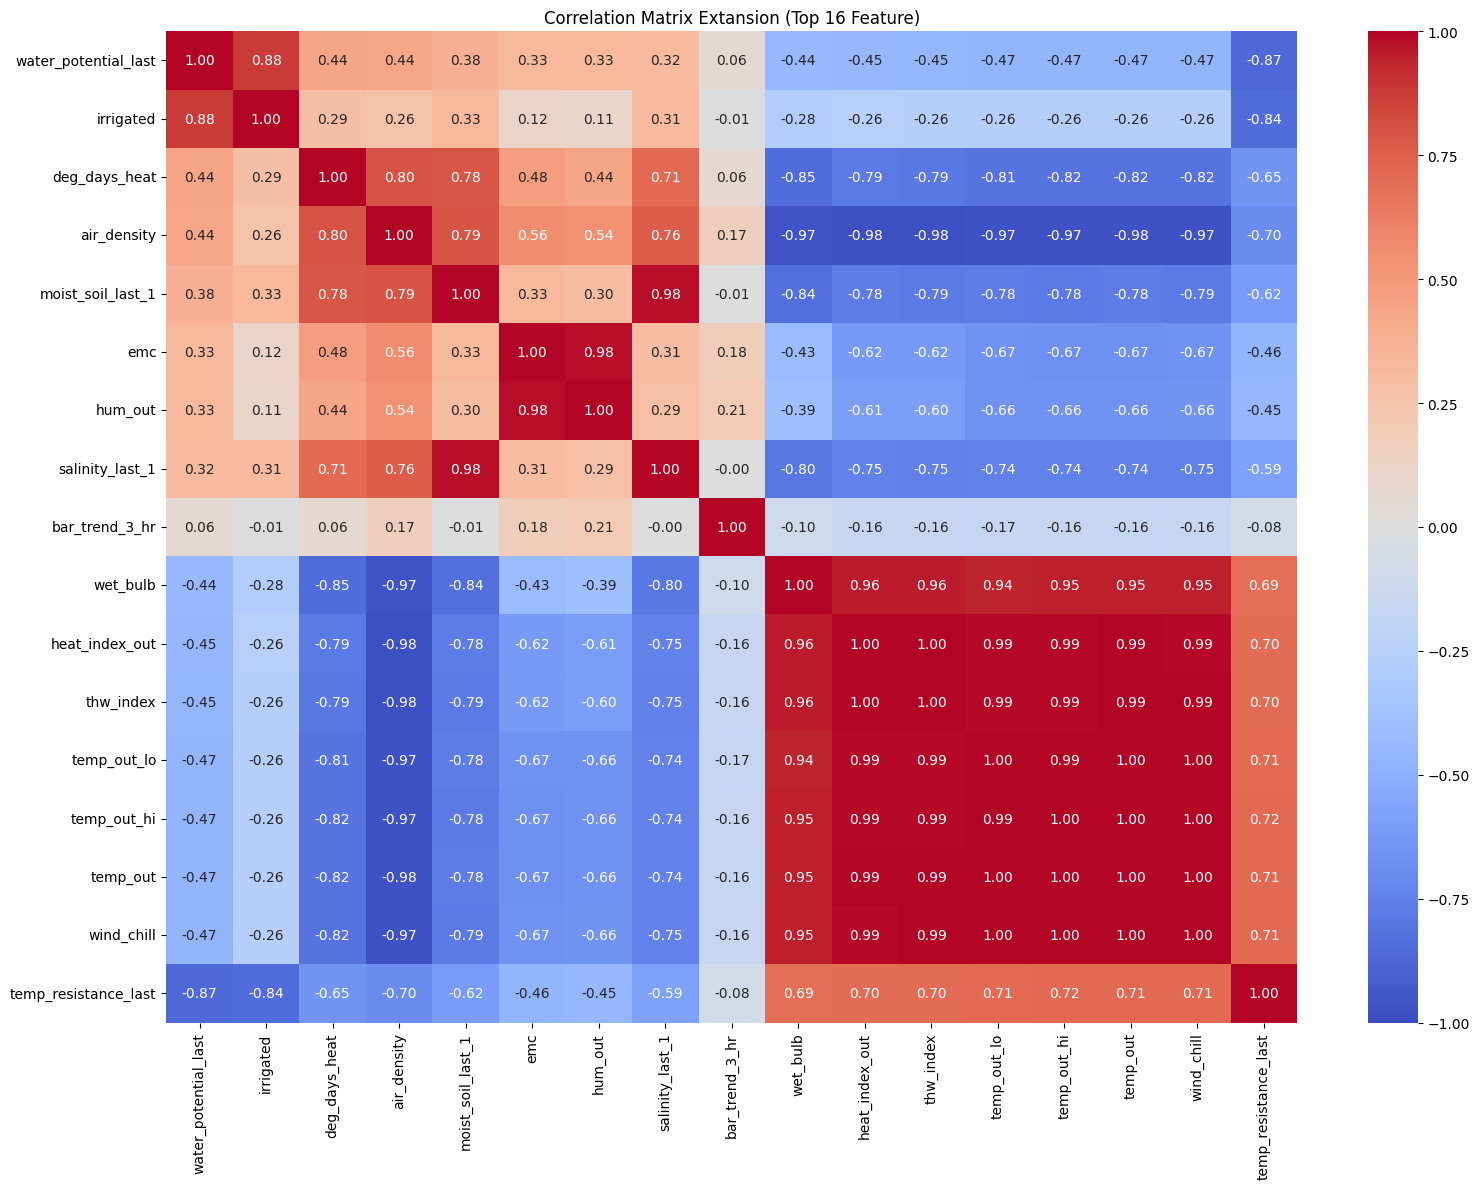

In [17]:
top_pos = corr_with_target.head(8).index.tolist()
top_neg = corr_with_target.tail(8).index.tolist()
top_features = ['water_potential_last'] + top_pos + top_neg

plt.figure(figsize=(16, 12))
corr_matrix_top = df_ml[top_features].corr()
sns.heatmap(corr_matrix_top, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix Extansion (Top 16 Feature)')
plt.tight_layout()
plt.show()

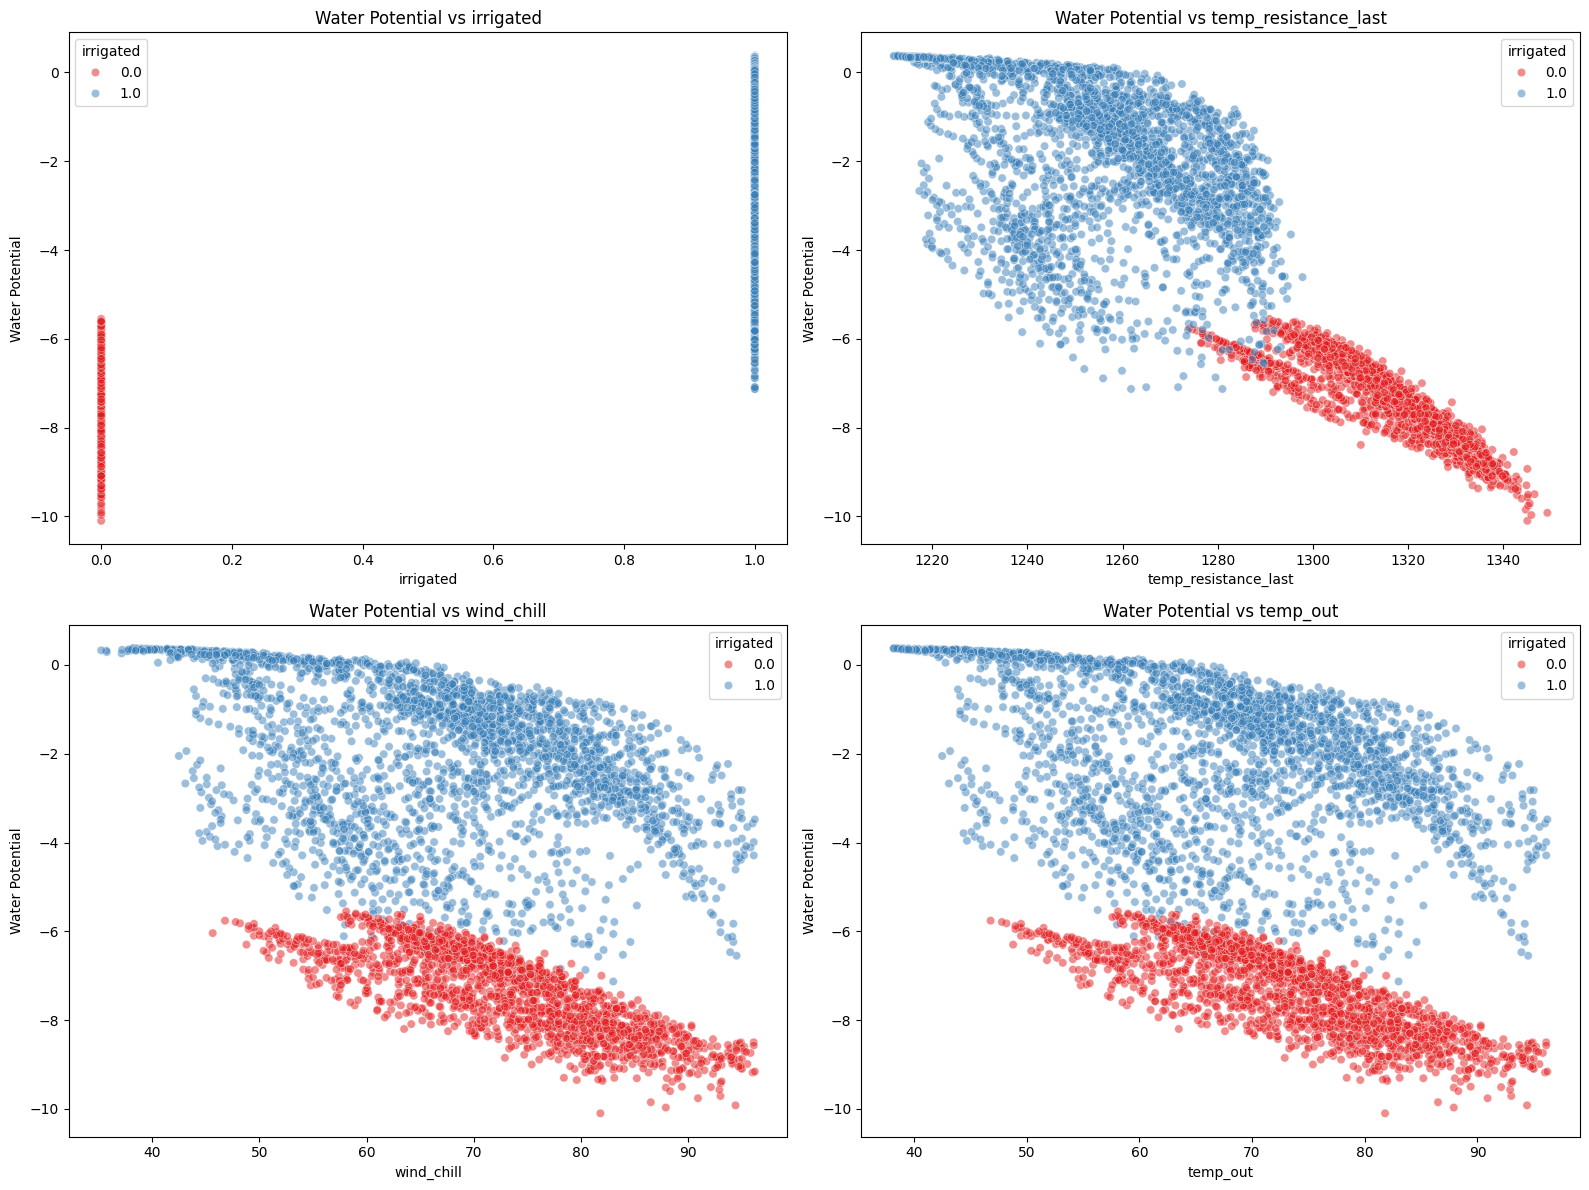

In [18]:
top_4_abs = corr_with_target.abs().sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(top_4_abs):
    sns.scatterplot(data=df_ml, x=col, y='water_potential_last', alpha=0.5, ax=axes[i], hue='irrigated', palette='Set1')
    axes[i].set_title(f'Water Potential vs {col}')
    axes[i].set_ylabel('Water Potential')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

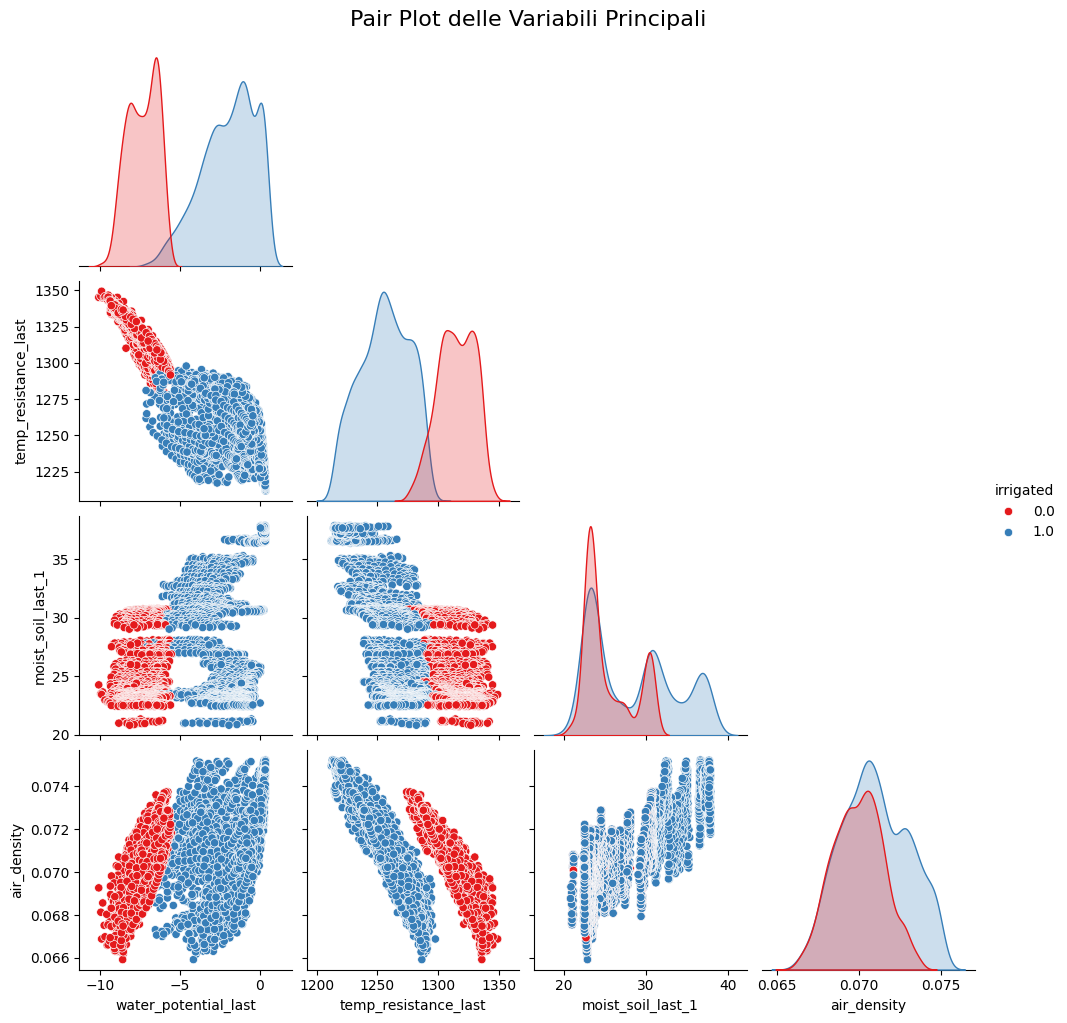

In [ ]:
features_to_plot = [
    'water_potential_last', 
    'temp_resistance_last', 
    'moist_soil_last_1', 
    'air_density',
    'irrigated' 
]

sns.pairplot(df_ml[features_to_plot], hue='irrigated', palette='Set1', diag_kind='kde', corner=True)

plt.suptitle('Pair Plot delle Variabili Principali', y=1.02, fontsize=16)
plt.show()